# Libraries importation

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.stats import chi2


# Data collection

## Assets selection and assets weights

In [2]:
print("================= Welcome to the Portfolio Risk Engine! =====================")
print()

nb_tickers = int(input("How many tickers does your portfolio contain? "))

tickers = []
tickers_category = []
weights = []

# Minimum 6 tickers
if nb_tickers < 6:
    print("Portfolio not Valid! You need at least 6 tickers")

else:
    for i in range(nb_tickers):

        # Validation of ticker
        while True:

            ticker = input(f"Enter the {i+1} asset ticker: ").upper().strip()

            # Vérifier les doublons
            if ticker in tickers:
                print("Ticker already entered! Please enter another ticker.")
                continue

            try:
                asset = yf.Ticker(ticker)
                info = asset.info

                category = info.get("quoteType")

                if not category:
                    print("Ticker not found! Please enter a valid ticker.")
                    continue

                # Ajouter uniquement les tickers valides
                tickers.append(ticker)
                tickers_category.append(category)

                print(f"Ticker validated: {ticker}")
                print(f"Asset category: {category}")

                break

            except Exception as e:
                print(f"Error retrieving ticker: {e}")
                print("Please try again.")

        # Validation du poids
        while True:

            try:
                weight = float(input(f"Enter the weight of {ticker} (between 0 and 1): "))

                if 0 < weight <= 1:
                    weights.append(weight)
                    print(f"Weight registered: {weight}")
                    break

                else:
                    print("Weight must be greater than 0 and less than or equal to 1.")

            except ValueError:
                print("Invalid weight! Please enter a number.")

    # Validation finale du portefeuille

    if len(set(tickers_category)) < 3:
        print("Portfolio not Valid! You need at least 3 different asset categories.")

    elif (sum(weights)!=1):
        print("Portfolio not Valid! Sum of weights must equal 1.")
        print(f"Current total weight: {sum(weights)}")

    else:
        print()
        print("================= PORTFOLIO VALIDATED =================")
        print(f"Tickers: {tickers}")
        print(f"Asset categories: {tickers_category}")
        print(f"Weights: {weights}")
        print(f"Total weight: {sum(weights)}")
        print(f"Number of asset categories: {len(set(tickers_category))}")

================= Welcome to the Portfolio Risk Engine! =====================

Ticker validated: AMZN
Asset category: EQUITY
Weight registered: 0.2
Ticker validated: GC=F
Asset category: FUTURE
Weight registered: 0.05
Ticker validated: GLD
Asset category: ETF
Weight registered: 0.1
Ticker validated: NVDA
Asset category: EQUITY
Weight registered: 0.3
Ticker validated: ^GSPC
Asset category: INDEX
Weight registered: 0.25
Ticker validated: BTC-USD
Asset category: CRYPTOCURRENCY
Weight registered: 0.1

================= PORTFOLIO VALIDATED =================
Tickers: ['AMZN', 'GC=F', 'GLD', 'NVDA', '^GSPC', 'BTC-USD']
Asset categories: ['EQUITY', 'FUTURE', 'ETF', 'EQUITY', 'INDEX', 'CRYPTOCURRENCY']
Weights: [0.2, 0.05, 0.1, 0.3, 0.25, 0.1]
Total weight: 1.0
Number of asset categories: 5


In [3]:
data = yf.download (tickers, start='2017-01-01', end='2023-01-01')['Close']
data = pd.DataFrame(data).dropna()
data

[*********************100%***********************]  6 of 6 completed


Ticker,AMZN,BTC-USD,GC=F,GLD,NVDA,^GSPC
Date,,,,,,
2017-01-03,37.683498,1043.839966,1160.400024,110.470001,2.506342,2257.830078
2017-01-04,37.859001,1154.729980,1163.800049,110.860001,2.564818,2270.750000
2017-01-05,39.022499,1013.380005,1179.699951,112.580002,2.499709,2269.000000
2017-01-06,39.799500,902.200989,1171.900024,111.750000,2.533123,2276.979980
2017-01-09,39.846001,902.828003,1183.500000,112.669998,2.635825,2268.899902
...,...,...,...,...,...,...
2022-12-23,85.250000,16796.953125,1804.199951,167.259995,15.155329,3844.820068
2022-12-27,83.040001,16717.173828,1823.099976,168.669998,14.073943,3829.250000
2022-12-28,81.820000,16552.572266,1815.800049,167.910004,13.989227,3783.219971


# Analytics & models

## Portfolio return calculation

In [4]:
daily_returns = data.pct_change().dropna() #rendements journaliers
assets_returns = daily_returns.mean (axis=0) #moyennes des rendements par actifs
print (assets_returns)


Ticker
AMZN       0.000758
BTC-USD    0.003005
GC=F       0.000344
GLD        0.000322
NVDA       0.001668
^GSPC      0.000433
dtype: float64


In [5]:
portfolio = pd.DataFrame (index=tickers , columns= ['Returns', 'Weights'], dtype = float)
portfolio ['Returns'] = assets_returns
portfolio ['Weights'] = weights
print (portfolio)

          Returns  Weights
AMZN     0.000758     0.20
GC=F     0.000344     0.05
GLD      0.000322     0.10
NVDA     0.001668     0.30
^GSPC    0.000433     0.25
BTC-USD  0.003005     0.10


In [6]:
portfolio_return = portfolio['Returns']*portfolio['Weights']
print(f"Expected Portfolio Return: {portfolio_return.sum() * 100:.4f} %")

Expected Portfolio Return: 0.1110 %


## Correlation heatmap

<Axes: xlabel='Ticker', ylabel='Ticker'>

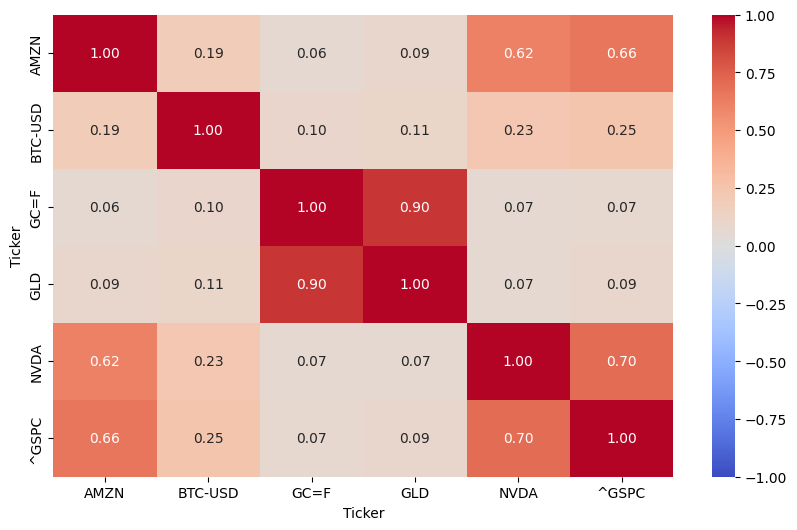

In [7]:
plt.figure(figsize=(10, 6))
sns.heatmap(daily_returns.corr(), vmin=-1, vmax=1, annot=True, cmap='coolwarm', fmt=".2f")

From this heatmap, we can observe : 
- a strong correlation between AMZN, NVDA, ^GSPC. The 2 stocks are ones of the most important in the S&P500 index, that explain the relation, two major companies operating in the same market
- GC=F and GLD are poorly correlated to all other assets. But they are strongly positively correlated, that what we expected. In fact, GLD is an ETF and GC=F is a future contract, and they have a same asset as underlying, the gold.
- Bitcoin has a weak correlation with all assets, this asset is highly volatile.

## Historical VaR

In [8]:
weights = pd.Series (portfolio ['Weights'] , index = daily_returns.columns)
print (weights)
pnl = daily_returns @ weights
#print (pnl)
sorted_pnl = pnl.sort_values(ascending=True)
print (sorted_pnl)


Ticker
AMZN       0.20
BTC-USD    0.10
GC=F       0.05
GLD        0.10
NVDA       0.30
^GSPC      0.25
Name: Weights, dtype: float64
Date
2020-03-12   -0.119078
2020-03-16   -0.108055
2022-06-13   -0.070540
2020-03-09   -0.065659
2022-09-13   -0.064580
                ...   
2020-03-17    0.067799
2020-04-06    0.069343
2020-03-13    0.076729
2020-03-24    0.091634
2022-11-10    0.096156
Length: 1508, dtype: float64


In [9]:
k_95 = len(sorted_pnl) * (0.05) # 5% quantile
k_99 = len(sorted_pnl) * (0.01) # 1% quantile
hist_var_95 = sorted_pnl.iloc [int(k_95)] # hist_var_95 = np.percentile(sorted_pnl, 5)
hist_var_99 = sorted_pnl.iloc [int(k_99)] # hist_var_99 = np.percentile(sorted_pnl, 1)


hist_cvar_95 = sorted_pnl [sorted_pnl <= hist_var_95].mean()  # Calculate CVaR as the mean of losses beyond VaR
hist_cvar_99 = sorted_pnl [sorted_pnl <= hist_var_99].mean()  # Calculate CVaR as the mean of losses beyond VaR

print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {-hist_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {-hist_cvar_99 * 100:.4f}% of its value in those cases.')

According to the historical method, the portfolio is expected to lose at least 2.6562% or more of its value in 5% of the worst cases and on average 4.0741% of its value in those cases.

According to the historical method, the portfolio is expected to lose at least 4.8598% or more of its value in 1% of the worst cases and on average 6.5561% of its value in those cases.


## Parametric VaR and CVaR

In [10]:
portfolio_std_dev = np.sqrt(np.dot(weights.T, np.dot(daily_returns.cov(), weights))) #écart type/volatilité du portefeuille

p_95 = 0.95
p_99 = 0.99

param_var_95 = (portfolio_return.sum() - (norm.ppf(p_95) * portfolio_std_dev))
param_var_99 = (portfolio_return.sum() - (norm.ppf(p_99) * portfolio_std_dev))

param_cvar_95 = - portfolio_return.sum() + (portfolio_std_dev * norm.pdf (norm.ppf(p_95)) / (1-p_95))
param_cvar_99 = - portfolio_return.sum() + (portfolio_std_dev * norm.pdf (norm.ppf(p_99)) / (1-p_99))

print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {param_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_99 * 100:.4f}% or more of its value in 1% of the worst cases on average {param_cvar_99 * 100:.4f}% of its value in those cases.\n')

According to the parametric method, the portfolio is expected to lose at least 2.7074% or more of its value in 5% of the worst cases and on average 3.4234% of its value in those cases.

According to the parametric method, the portfolio is expected to lose at least 3.8751% or more of its value in 1% of the worst cases on average 4.4557% of its value in those cases.



## n-days parametric VaR and CVaR

In [11]:
horizon = 10 #parameter for the n-day VaR or CVaR

d_param_var_95 = - (portfolio_return.sum() * horizon - (norm.ppf(p_95) * np.sqrt (horizon) * portfolio_std_dev))
d_param_var_99 = - (portfolio_return.sum() * horizon - (norm.ppf(p_99) * np.sqrt (horizon) * portfolio_std_dev))

d_param_cvar_95 = - portfolio_return.sum() * horizon + (np.sqrt (horizon) * portfolio_std_dev * norm.pdf (norm.ppf(p_95)) / (1-p_95))
d_param_cvar_99 = - portfolio_return.sum() * horizon + (np.sqrt (horizon) * portfolio_std_dev * norm.pdf (norm.ppf(p_99)) / (1-p_99))

print (f'10-days 95 parametric VaR : {d_param_var_95*100:.4f}%\n'
       f'10-days 99 parametric VaR : {d_param_var_99*100:.4f}%\n'
       f'10-days 95 parametric CVaR : {d_param_cvar_95*100:.4f}%\n'
       f'10-days 99 parametric CVaR : {d_param_cvar_99*100:.4f}%\n')

10-days 95 parametric VaR : 7.8023%
10-days 99 parametric VaR : 11.4950%
10-days 95 parametric CVaR : 10.0665%
10-days 99 parametric CVaR : 13.3311%



# Simulation Monte Carlo

## Simulations des trajectoires

In [12]:
def simulation_gbm (weights, returns, cov, S0 = 1.0, n_days = 252, n_sim = 10000) : 
    np.random.seed (42)
    dt = 1
    
    returns = np.asarray (returns)
    port_values = np.zeros ((n_sim, n_days+1))
    port_values [:,0] = S0

    
    z = np.random.multivariate_normal (np.zeros(len(returns)), cov * dt, size=(n_sim, n_days))  #Composant aléatoire pour la simulation
            
    for t in range  (1, n_days + 1) : 
        asset_returns = (returns - 0.5 * np.diag(cov)) * dt + z [:, t-1]
        port_return = asset_returns @ weights
        port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

    return port_values

In [13]:
simulated_portfolio_values = simulation_gbm (weights, assets_returns, daily_returns.cov(), n_days = 10) #n_days = 10 for a 10-day VaR
print (simulated_portfolio_values)

[[1.         0.99223294 0.98278711 ... 0.96444557 0.94233956 0.94109756]
 [1.         1.00374613 1.01809734 ... 1.0203981  1.01513918 1.02198551]
 [1.         0.98238099 0.99051878 ... 0.95280876 0.94796041 0.95339775]
 ...
 [1.         0.97846295 0.99382817 ... 0.97297754 0.98538918 0.97478714]
 [1.         1.02656779 1.02453418 ... 1.03471957 1.04016406 1.02124203]
 [1.         0.99380435 0.97831848 ... 1.04556986 1.07717385 1.09174033]]


## Calcul VaR et CVaR

In [14]:
loss = simulated_portfolio_values[:,-1] - simulated_portfolio_values[:,0]
mc_var_95 = np.percentile(loss, 5)
mc_var_99 = np.percentile(loss, 1)
mc_cvar_95 = np.mean(loss[loss <= mc_var_95])
mc_cvar_99 = np.mean(loss[loss <= mc_var_99])

print (f'According to the Monte Carlo simulation, on a 10-day period the portfolio is expected to lose at least {-mc_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {- mc_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the Monte Carlo simulation, on a 10-day period the portfolio is expected to lose at least {-mc_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {- mc_cvar_99 * 100:.4f}% of its value in those cases.')

According to the Monte Carlo simulation, on a 10-day period the portfolio is expected to lose at least 8.0864% or more of its value in 5% of the worst cases and on average 10.0614% of its value in those cases.

According to the Monte Carlo simulation, on a 10-day period the portfolio is expected to lose at least 11.3490% or more of its value in 1% of the worst cases and on average 12.9265% of its value in those cases.


# Stress test : correlation stress

In [15]:
#Covariance matrix reconstruction test

std = daily_returns.std () 
corr = daily_returns.corr ()
cov = np.diag (std) @ corr @ np.diag (std)
print (np.allclose (cov, daily_returns.cov())) #check if the new cov mat is equal to the original one


corr_stress = (1 - 0.75) * corr + 0.75 * np.ones_like (daily_returns.corr())
cov_stress = np.diag (std) @ corr_stress @ np.diag (std)
print (np.allclose (cov_stress, cov)) #check if the new cov mat is equal to the original one
print (np.allclose (np.diag (cov_stress), std**2)) #the new cov mat has the same variance as the daily returns
display (cov_stress)

True
False
True


,0,1,2,3,4,5
0,0.000454,0.000818,0.000151,0.000142,0.000608,0.000247
1,0.000818,0.002316,0.000345,0.000323,0.001229,0.000496
2,0.000151,0.000345,0.000086,0.000078,0.000224,0.000090
3,0.000142,0.000323,0.000078,0.000075,0.000209,0.000085
4,0.000608,0.001229,0.000224,0.000209,0.000998,0.000371
5,0.000247,0.000496,0.000090,0.000085,0.000371,0.000161


We test a way to rebuild the initial covariance matrix while having the same variance for each asset.

In [16]:
coef = np.asarray ([0, 0.25, 0.5, 0.75, 1])
stress_test_table = pd.DataFrame (index=coef,columns=('Port std','VaR param', 'VaR MC', 'CVaR param', 'CVaR MC'), dtype= float)
risk_contribution_table = pd.DataFrame (index=coef, columns=tickers, dtype= float)

for i in coef :
    #Covariance matrix recomposition
    corr_stress = (1 - i) * corr + i * np.ones_like (corr)
    cov_stress = np.dot (np.diag (std), np.dot (corr_stress, np.diag (std)))

    #Parametric VaR calculation
    std_stress = np.sqrt(weights.T @ cov_stress @ weights)
    p_95 = 0.95
    param_var = - (portfolio_return.sum() - (norm.ppf(p_95) * std_stress))
    param_cvar = - portfolio_return.sum() + (std_stress * norm.pdf (norm.ppf(p_95)) / (1-p_95))
    stress_test_table.loc [i,'VaR param'] = param_var
    stress_test_table.loc [i, 'CVaR param'] = param_cvar
    stress_test_table.loc [i, 'Port std'] = std_stress

    #Monte-Carlo VaR calculation
    stress_value = simulation_gbm (weights, assets_returns, cov_stress, n_days = 1) #n_days = 1 pour calculer la VaR à 1 jour
    stress_loss = stress_value[:,-1] - stress_value[:,0]
    st_mc_var = np.percentile(stress_loss, 5)
    st_mc_cvar = np.mean(stress_loss[stress_loss <= st_mc_var])
    stress_test_table.loc [i,'VaR MC'] = - st_mc_var
    stress_test_table.loc [i, 'CVaR MC'] = - st_mc_cvar

    #Volatility contribution calculation
    mrc = cov_stress @ weights / std_stress   #marginal risk contribution
    RC = mrc * weights  #risk contribution per asset
    risk_contribution_table.loc[i,:] = RC


print (stress_test_table.round (4))
print ()
risk_contribution_table ['Portfolio volatility'] = risk_contribution_table.sum(axis=1)
print (f'Risk Contribution Table (absolute values):\n'
        f'{risk_contribution_table.round (4)}')
print ()
print (f'Risk Contribution Table (normalized values):\n'
        f'{risk_contribution_table.div(risk_contribution_table["Portfolio volatility"], axis=0).round(4)}')



      Port std  VaR param  VaR MC  CVaR param  CVaR MC
0.00    0.0171     0.0271  0.0271      0.0342   0.0337
0.25    0.0188     0.0298  0.0294      0.0376   0.0370
0.50    0.0203     0.0323  0.0321      0.0408   0.0401
0.75    0.0217     0.0346  0.0345      0.0437   0.0430
1.00    0.0231     0.0368  0.0368      0.0464   0.0456

Risk Contribution Table (absolute values):
        AMZN    GC=F     GLD    NVDA   ^GSPC  BTC-USD  Portfolio volatility
0.00  0.0033  0.0001  0.0002  0.0086  0.0026   0.0025                0.0171
0.25  0.0036  0.0002  0.0004  0.0088  0.0027   0.0032                0.0188
0.50  0.0038  0.0003  0.0006  0.0090  0.0029   0.0038                0.0203
0.75  0.0040  0.0004  0.0007  0.0092  0.0030   0.0043                0.0217
1.00  0.0043  0.0005  0.0009  0.0095  0.0032   0.0048                0.0231

Risk Contribution Table (normalized values):
        AMZN    GC=F     GLD    NVDA   ^GSPC  BTC-USD  Portfolio volatility
0.00  0.1916  0.0045  0.0091  0.5012  0.1502   0

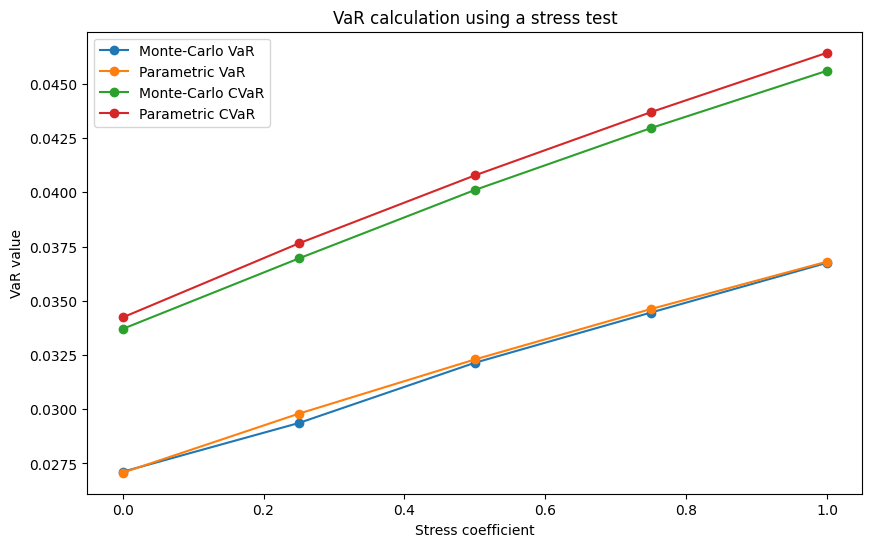

In [17]:
plt.figure (figsize= (10,6))
plt.plot (stress_test_table.index, stress_test_table ['VaR MC'], marker='o', label = 'Monte-Carlo VaR')
plt.plot (stress_test_table.index, stress_test_table ['VaR param'], marker = 'o', label = 'Parametric VaR')
plt.plot (stress_test_table.index, stress_test_table ['CVaR MC'], marker='o', label = 'Monte-Carlo CVaR')
plt.plot (stress_test_table.index, stress_test_table ['CVaR param'], marker='o', label = 'Parametric CVaR')
plt.title ('VaR calculation using a stress test')
plt.xlabel ('Stress coefficient')
plt.ylabel ('VaR value')
plt.legend ()
plt.show ()

# Backtesting

## Test de Kupiec

In [18]:
n = len (pnl)
x = pnl [pnl < - param_var_95].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_95 #theorical/expected probability of failure
p = x/n  # real probability of failure

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio

print (f'===============  Niveau de confiance : {p_95*100}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')

if LR <= chi2.ppf (0.95, df = 1) :  #corresponds to the chi-squared distribution for a 5% significance level
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 95.0%  ===============
Probabilité d'échecs observée : 0.9456
Ratio de vraisemblance : 7915.2440
Ecart trop grand, modèle de VaR rejeté


In [19]:
n = len (pnl)
x = pnl [pnl < - param_var_99].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_99 #probabilité d'échecs théorique
p = x/n  #probabilité d'échecs observée

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio
print (f'===============  Niveau de confiance : {p_99*100}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')


if LR <= chi2.ppf (0.95, df = 1) :  #corresponds to the chi-squared distribution for a 5% significance level
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 99.0%  ===============
Probabilité d'échecs observée : 0.9861
Ratio de vraisemblance : 13474.9833
Ecart trop grand, modèle de VaR rejeté


## Rolling backtesting

In [20]:
#Dans cette étape, on va calculer la VaR quotidienne en ajustant nos données à chaque fois sur les 250 derniers jours (soit 1 an)

w = 250 #longueur de la fenêtre, le nombre de jours ouvrés (trading days) sur 1 an
n = len (daily_returns)
window = pd.DataFrame(index=daily_returns.index, columns=['Daily Returns', 'VaR'], dtype=float)
window ['Daily Returns'] = pnl
for i in range (w, n) :
    window_ret = daily_returns.iloc [i-w:i]
    window_port_ret = window_ret.mean (axis= 0) * weights
    window_port_std = np.sqrt (weights.T @ window_ret.cov() @ weights)
    window_var = window_port_ret.sum() - (norm.ppf(p_95) * window_port_std)
    window.iloc [i, 1] = window_var
print (window)

            Daily Returns       VaR
Date                               
2017-01-04       0.020484       NaN
2017-01-05      -0.011668       NaN
2017-01-06      -0.003167       NaN
2017-01-09       0.012897       NaN
2017-01-10      -0.001528       NaN
...                   ...       ...
2022-12-23       0.002700 -0.039898
2022-12-27      -0.026711 -0.039830
2022-12-28      -0.009385 -0.039993
2022-12-29       0.023636 -0.040027
2022-12-30      -0.000602 -0.039998

[1508 rows x 2 columns]


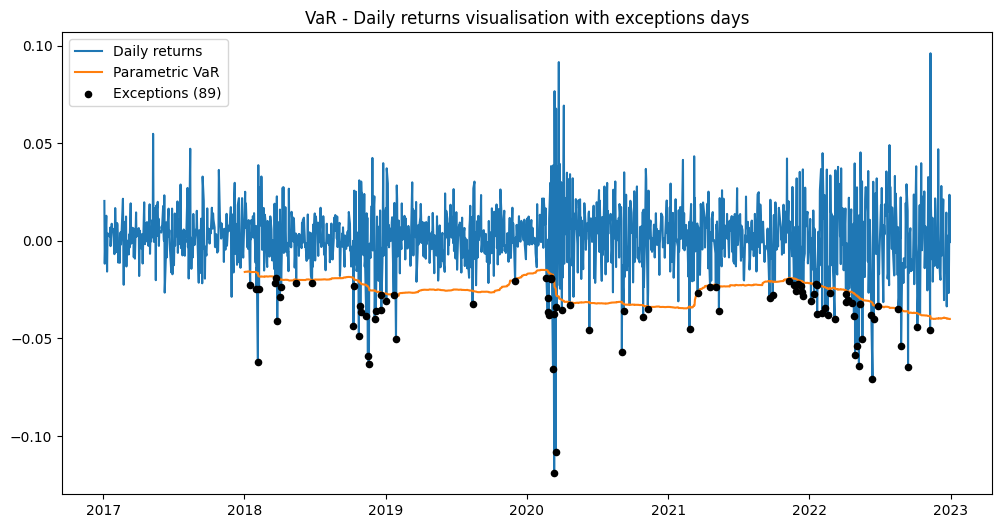

In [21]:
exceptions = window[window['Daily Returns'] < window['VaR']]

plt.figure (figsize= (12,6))
plt.plot (window.index, window ['Daily Returns'], label = 'Daily returns')
plt.plot (window.index, window ['VaR'], label = 'Parametric VaR')
plt.scatter(exceptions.index, exceptions['Daily Returns'],
            color='black', s=20, zorder=3, label=f'Exceptions ({len(exceptions)})')
plt.legend ()
plt.title ('VaR - Daily returns visualisation with exceptions days')
plt.show()

In [22]:
window_clean = window[window['VaR'].notna()]

print (f'This rolling window model shows that we have {len (exceptions)} exception days out of {len (window_clean)},' 
       f'this is {len(exceptions)*100/len(window_clean):.2f}% days.\n' 
       f'As we expected a 5% ({0.05 * len(window_clean):.4f}) days of exceptions')

if len (exceptions) > 0.05 * len (window_clean) :
    print ('The VaR rolling window model for 250-day is not the best fitted model for our risk management')
else : 
    print ('The VaR rolling window model can be accepted for our risk management')

This rolling window model shows that we have 89 exception days out of 1258,this is 7.07% days.
As we expected a 5% (62.9000) days of exceptions
The VaR rolling window model for 250-day is not the best fitted model for our risk management
